等待用户输入 审查工具调用 编辑图的状态

In [1]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, interrupt
from langgraph.checkpoint.memory import MemorySaver
from IPython.display import Image, display

class State(TypedDict):
    input: str            # 用户输入的查询或指令
    user_feedback: str    # 用于存储用户反馈（通常配合 interrupt 使用）

def step_1(state: State):
    print("----step1----")
    pass
def human_feedback(state: State):
    print("----human_feedback----")
    feedback = interrupt("请输入反馈") #这个组件就是打断图流的工具 下面用command重新启动流程
    print("human_feedback:", feedback)
def step_3(state: State):
    print("----step2----")

In [2]:
# 初始化图，传入之前定义好的 State 类
builder = StateGraph(State)

# 添加节点 (Node Name, Function/Runnable)
builder.add_node("step_1", step_1)
builder.add_node("human_feedback", human_feedback)
builder.add_node("step_3", step_3)

# 建立连接关系 (From, To)
builder.add_edge(START, "step_1")                  # 从起点进入步骤1
builder.add_edge("step_1", "human_feedback")       # 步骤1完成后进入人工反馈环节
builder.add_edge("human_feedback", "step_3")       # 人工反馈完成后进入步骤3
builder.add_edge("step_3", END)                    # 步骤3完成后结束
memory = MemorySaver()

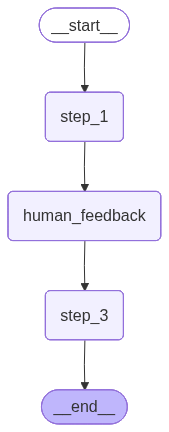

In [3]:
# Add (编译并挂载检查点)
graph = builder.compile(checkpointer=memory)

# View (可视化图结构)
display(Image(graph.get_graph().draw_mermaid_png()))

In [4]:
# Input (定义初始输入)
initial_input = {"input": "你好"}

# Thread (定义线程，用于持久化记忆)
thread = {"configurable": {"thread_id": "1"}}

# Run the graph until the first interruption (运行图直至第一次中断)
for event in graph.stream(initial_input, thread, stream_mode="updates"):
    print(event)
    print("\n")

----step1----
{'step_1': None}


----human_feedback----
{'__interrupt__': (Interrupt(value='请输入反馈', id='135afb65b22852276527c3d595ad3711'),)}




In [5]:
# 继续执行
for event in graph.stream(
    Command(resume="go to step 3!"), thread, stream_mode="updates" #command和interrupt配合使用
):
    print(event)
    print("\n")

----human_feedback----
human_feedback: go to step 3!
{'human_feedback': None}


----step2----
{'step_3': None}


